[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter01_Forecasting_Landscape/01_Forecasting_Zoo.ipynb)

# Chapter 1: The Forecasting Zoo

**Hands-On Open-Source Foundation Models for Time Series Forecasting**  
Tanujit Chakraborty and Shovon Sengupta

This guided notebook inspects the **saved, actually executed** ETTh1 experiment. It verifies the scores from the retained predictive samples and explores the figures without downloading weights or rerunning any model. The original CPU run compared AutoARIMA, N-HiTS–Normal, and the original `amazon/chronos-t5-small` at three fixed origins, with a 96-hour horizon and 128 samples per method and origin.

Run the cells in order from the chapter directory or the repository root. For a local run, install `requirements-inspect.txt` in a Python 3.12 environment and select that environment as the notebook kernel; see [README.md](README.md). In Google Colab, the setup cell clones the repository and installs this inspection environment automatically. After setup, the default cells use the bundled data and saved results without network access or model dependencies.

The optional model-rerun command at the end requires the full environment described in the README. New outputs go into `runs/`; the results quoted in the book remain unchanged.

**Learning goal:** explain what each model saw, reproduce MAE/sMAPE/CRPS, and distinguish useful uncertainty from a narrow interval. This is a bounded teaching experiment, not a general model ranking.


In [1]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys

CHAPTER = "Chapter01_Forecasting_Landscape"
REPO = "https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting.git"
# Optional Colab preview before the chapter is pushed: mount Drive yourself,
# then set this to your complete chapter folder (not just the notebook).
DRIVE_COPY = None  # e.g. "/content/drive/MyDrive/Chapter01_Forecasting_Landscape"

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False

if IN_COLAB:
    if DRIVE_COPY:
        candidate = Path(DRIVE_COPY).expanduser()
        if not candidate.is_dir():
            raise FileNotFoundError("Mount Google Drive and set DRIVE_COPY to the complete chapter folder.")
    else:
        checkout = Path("/content/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting")
        if not checkout.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO, str(checkout)], check=True)
        candidate = checkout / CHAPTER
    if not (candidate / "requirements-inspect.txt").is_file():
        raise FileNotFoundError("The Chapter 1 folder is missing. Push it to GitHub or use DRIVE_COPY.")
    os.chdir(candidate)
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "-r", "requirements-inspect.txt"],
                   check=True)

# Also handles a checkout under an arbitrarily named parent directory.
working = Path.cwd().resolve()
candidates = []
for parent in (working, *working.parents):
    candidates.extend((parent, parent / CHAPTER))
ROOT = next((p for p in candidates
             if (p / "results/manifest.json").is_file()
             and (p / "src/ch01_forecasting/metrics.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the complete Chapter 1 folder, a subfolder, or the repository root.")
ROOT = ROOT.resolve()
source_path = str(ROOT / "src")
if source_path not in sys.path:
    sys.path.insert(0, source_path)
print("Chapter folder:", ROOT.name)
print("Default workflow: inspect saved outputs; no models are trained or called.")


Chapter folder: Chapter01_Forecasting_Landscape
Default workflow: inspect saved outputs; no models are trained or called.


In [2]:
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from ch01_forecasting.metrics import ensemble_crps, score_forecast, verify_scores
from ch01_forecasting.feature_example import lagged_training_rows

manifest = json.loads((ROOT / "results/manifest.json").read_text())
metrics = pd.read_csv(ROOT / "results/metrics.csv")
print("Saved experiment status:", manifest["status"])
print("Origins:", manifest["origins"], "| Horizon:", manifest["horizon"])
print("Samples per origin:", manifest["n_samples"], "| Device:", manifest["device"])


Saved experiment status: executed
Origins: [11520, 11616, 11712] | Horizon: 96
Samples per origin: 128 | Device: CPU


## 1. Check the data boundary before comparing models

The target is hourly transformer oil temperature, `OT`, in degrees Celsius. The original Informer convention uses split endpoints **8,640 / 11,520 / 14,400** (end-exclusive indices), which correspond to fixed 30-day blocks rather than exact calendar months. Only the three prespecified windows starting at 11,520, 11,616 and 11,712 are scored here. Their 96-hour targets do not overlap.

Different training regimes remain visible: AutoARIMA refits on all available past observations; N-HiTS has a fixed 200-step training budget and frozen weights at test time; Chronos uses its preceding 512 observations with frozen pretrained weights. Equal target times do not imply equal training costs or history lengths.


In [3]:
data_path = ROOT / "data/ETTh1.csv"
digest = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert digest == manifest["data_sha256"], "The dataset differs from the recorded run."
raw = pd.read_csv(data_path, parse_dates=["date"])
assert raw.date.is_monotonic_increasing and raw.date.is_unique
assert raw.date.diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert raw.OT.notna().all() and np.isfinite(raw.OT).all()
for origin in manifest["origins"]:
    stop = origin + manifest["horizon"]
    print(f"[{origin}, {stop}): {raw.date.iloc[origin]} to {raw.date.iloc[stop-1]}")
print("Dataset checksum and hourly timestamp checks passed.")


[11520, 11616): 2017-10-24 00:00:00 to 2017-10-27 23:00:00
[11616, 11712): 2017-10-28 00:00:00 to 2017-10-31 23:00:00
[11712, 11808): 2017-11-01 00:00:00 to 2017-11-04 23:00:00
Dataset checksum and hourly timestamp checks passed.


## 2. Read the measured comparison

MAE and CRPS are in degrees Celsius; sMAPE is a percentage. Coverage is stored as a proportion. Point predictions are the analytic Normal median for AutoARIMA and N-HiTS–Normal, and the sample median for Chronos. Every displayed interval is computed from the same sample count.

Read accuracy alongside coverage and interval width. A very wide interval may cover almost everything while being unhelpful; a narrow interval may miss much of what happens. These 288 dependent targets do not establish general calibration.


In [4]:
shown = metrics[["model", "MAE", "sMAPE_percent", "CRPS", "coverage_80", "width_80", "coverage_95", "width_95"]].copy()
shown["coverage_80"] *= 100
shown["coverage_95"] *= 100
shown = shown.rename(columns={"coverage_80": "coverage80_percent", "coverage_95": "coverage95_percent"})
print(shown.to_string(index=False, float_format=lambda value: f"{value:.3f}"))


           model   MAE  sMAPE_percent  CRPS  coverage80_percent  width_80  coverage95_percent  width_95
       AutoARIMA 1.837         18.956 1.330              95.139     8.672              98.958    12.936
    NHITS-Normal 2.021         20.748 1.364              81.250     6.587              95.833     9.831
Chronos-T5-Small 2.209         22.908 1.754              33.681     2.600              49.306     4.622


**Inspect before continuing.** Which model has the lowest CRPS in this run? Which has coverage closest to 80%? Are those necessarily the same criterion? Explain why the smallest width alone cannot select a good forecast.

## 3. Verify the scorer and reproduce every saved row

For samples $x_1,\ldots,x_M$ at one target $y$, the empirical-ensemble score is

$$\widehat{\mathrm{CRPS}}=\frac{1}{M}\sum_i|x_i-y|-\frac{1}{2M^2}\sum_{i,j}|x_i-x_j|.$$

The implementation includes the diagonal pairs. It scores the finite empirical distribution and does not apply the fair-ensemble correction. Scores below average marginal CRPS across target times; they do not test the temporal dependence between future observations.


In [5]:
print(verify_scores())
recomputed_rows = []
for model in metrics.model:
    slug = model.lower().replace("-", "_")
    saved_scores = pd.read_csv(ROOT / "results" / f"{slug}_scores.csv").set_index("origin_index")
    with np.load(ROOT / "results" / f"{slug}_samples.npz", allow_pickle=False) as saved:
        for origin in manifest["origins"]:
            actual = saved[f"actual_{origin}"]
            samples = saved[f"samples_{origin}"]
            point = saved[f"point_{origin}"]
            assert samples.shape == (manifest["n_samples"], manifest["horizon"])
            assert point.shape == actual.shape == (manifest["horizon"],)
            assert np.isfinite(samples).all() and np.isfinite(point).all()
            np.testing.assert_allclose(actual, raw.OT.iloc[origin:origin+manifest["horizon"]])
            if model == "Chronos-T5-Small":
                np.testing.assert_allclose(point, np.median(samples, axis=0))
            row_scores = score_forecast(actual, samples, point)
            for metric, value in row_scores.items():
                np.testing.assert_allclose(value, saved_scores.loc[origin, metric], rtol=1e-12, atol=1e-12)
            recomputed_rows.append({"model": model, "origin_index": origin, **row_scores})
recomputed = pd.DataFrame(recomputed_rows)
recomputed_mean = recomputed.drop(columns="origin_index").groupby("model", sort=False).mean()
for row in metrics.itertuples(index=False):
    for metric in recomputed_mean.columns:
        np.testing.assert_allclose(recomputed_mean.loc[row.model, metric], getattr(row, metric),
                                   rtol=1e-12, atol=1e-12)
print("All 9 model-origin arrays reproduce the saved per-origin and aggregate scores.")
print(recomputed[["model", "origin_index", "MAE", "CRPS", "coverage_80"]].to_string(index=False))


{'optimized_crps_vs_pairwise': 'passed', 'perfect_forecast': 'passed', 'smape_zero_and_opposite_sign': 'passed'}
All 9 model-origin arrays reproduce the saved per-origin and aggregate scores.
           model  origin_index      MAE     CRPS  coverage_80
       AutoARIMA         11520 1.568797 1.204205     0.989583
       AutoARIMA         11616 1.853793 1.319548     0.958333
       AutoARIMA         11712 2.087730 1.465562     0.906250
    NHITS-Normal         11520 1.701612 1.151525     0.937500
    NHITS-Normal         11616 2.294437 1.529509     0.885417
    NHITS-Normal         11712 2.068268 1.411943     0.614583
Chronos-T5-Small         11520 1.884971 1.486311     0.500000
Chronos-T5-Small         11616 2.225507 1.654128     0.468750
Chronos-T5-Small         11712 2.517272 2.122093     0.041667


**Try it.** Change only the number of retained samples used for scoring, for example to the first 32 or 64. Compare CRPS and tail intervals with the 128-sample calculation. Keep that sensitivity exercise separate from the recorded comparison; it does not create a new trained model.

## 4. Inspect the same forecast window for all models

The plotted window is the first fixed origin. The three panels share observations and target times. Shading represents central 80% and 95% marginal intervals. These curves were produced from actual saved model outputs, whereas the later decomposition and stationarity figures are explicitly synthetic teaching illustrations.


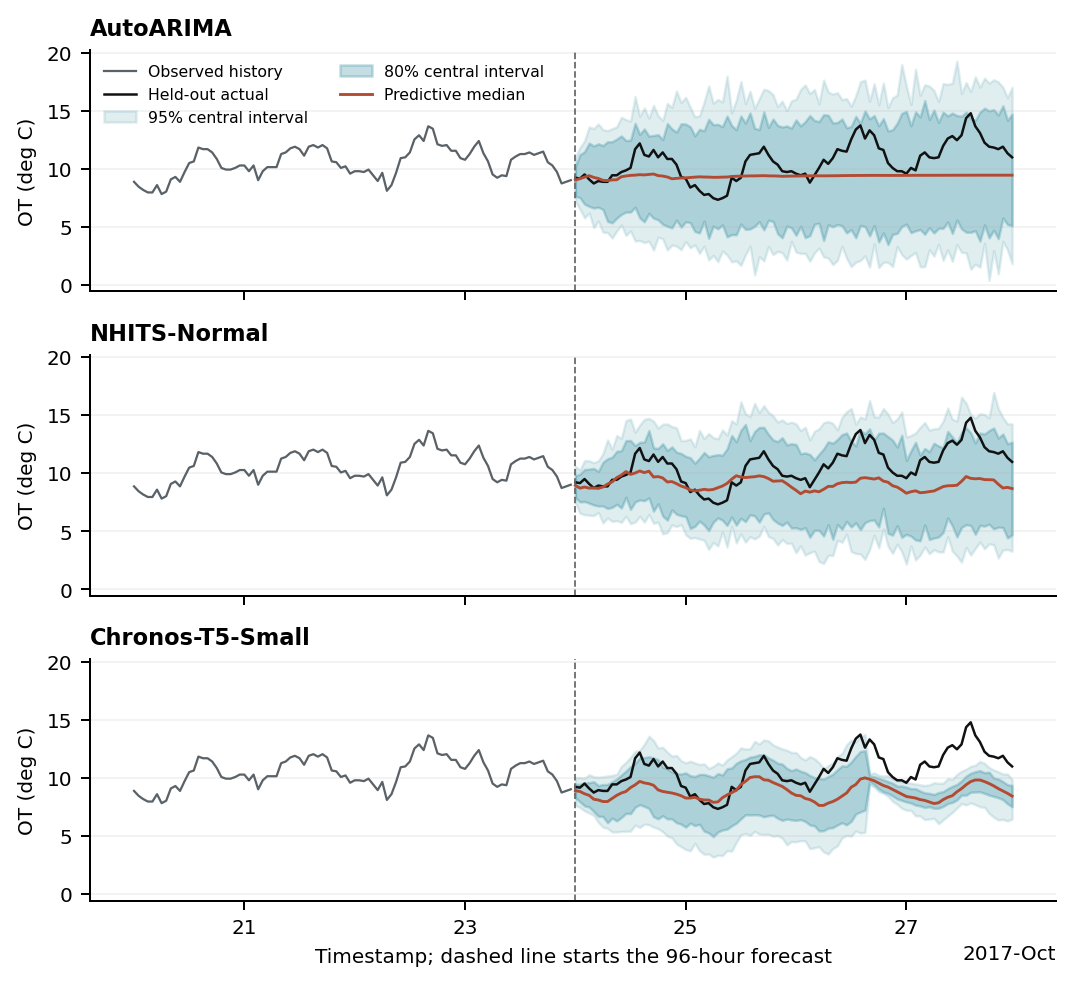

In [6]:
display(Image(filename=str(ROOT / "figures/zoo_forecasts.png")))


The original Chronos-T5 checkpoint has a native prediction length of 64. This exercise requests 96 steps: the pinned pipeline extends the forecast by appending the previous generated chunk's median to the context. Joint path uncertainty is therefore not fully propagated beyond the first chunk. “Zero-shot” here means frozen weights; whether ETTh1 appeared in its pretraining data is recorded as unknown.

## 5. Check performance across origins

An aggregate hides changes from one window to another. The next plot displays the three per-origin CRPS values without treating them as independent repeated trials. These few origins are an instructional diagnostic, not enough to estimate a robust ranking or a confidence interval for superiority.


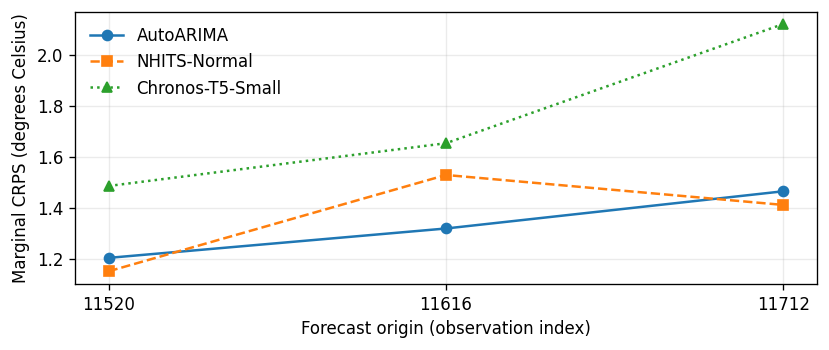

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
styles = [("o", "-"), ("s", "--"), ("^", ":")]
for (model, group), (marker, linestyle) in zip(recomputed.groupby("model", sort=False), styles):
    ax.plot(group.origin_index, group.CRPS, marker=marker, linestyle=linestyle, label=model)
ax.set_xlabel("Forecast origin (observation index)")
ax.set_ylabel("Marginal CRPS (degrees Celsius)")
ax.set_xticks(manifest["origins"])
ax.grid(alpha=.25)
ax.legend(frameon=False)
fig.tight_layout()
display(fig)
plt.close(fig)


**Try it.** Use `coverage_80` and `width_80` to draw two companion panels. Discuss why a method can improve its coverage merely by widening intervals, and why CRPS considers the predictive distribution as a whole.

## 6. Align a supervised-learning row correctly

A tree model needs an explicit feature table. This deterministic integer ramp makes leakage easy to detect. Each row is indexed by its target time. `mean_24` is shifted before rolling, so the current target is excluded. Hour of day is genuinely known in advance; a future observed load measurement is not.


In [8]:
toy = pd.Series(np.arange(72, dtype=float),
                index=pd.date_range("2020-01-01", periods=72, freq="h"))
features = lagged_training_rows(toy)
print(features.head(2).to_string())
assert features.iloc[0]["target"] == 24
assert features.iloc[0]["lag_1"] == 23
assert features.iloc[0]["lag_24"] == 0
assert features.iloc[0]["mean_24"] == 11.5
changed = toy.copy()
changed.iloc[24] = -999
pd.testing.assert_series_equal(features.iloc[0].drop("target"),
                               lagged_training_rows(changed).iloc[0].drop("target"))
print("Changing the target leaves its own features unchanged.")


                     target  lag_1  lag_24  mean_24  hour
2020-01-02 00:00:00    24.0   23.0     0.0     11.5     0
2020-01-02 01:00:00    25.0   24.0     1.0     12.5     1
Changing the target leaves its own features unchanged.


**Try it.** Replace `y.shift(1).rolling(24).mean()` with `y.rolling(24).mean()` in a temporary function. Identify the target value that has entered its own predictor. For multi-step forecasting, also check whether each lag is available at the original issue time, rather than only at the later target time.

## 7. Inspect the original teaching figures

These saved illustrations use declared random seeds and specified synthetic processes. They explain decomposition, stationarity, pointwise uncertainty and learning regimes. No synthetic value is inserted into the ETTh1 result table.

To regenerate all four figures in a separate output directory, run `python scripts/make_teaching_figures.py` from the chapter folder. The script prints the new output location under `runs/`; it does not replace the bundled figures.


Teaching figures: decomposition, stationarity, uncertainty, learning_regimes
Provenance: Original code-generated synthetic illustrations; no sample-book artwork or empirical model results.


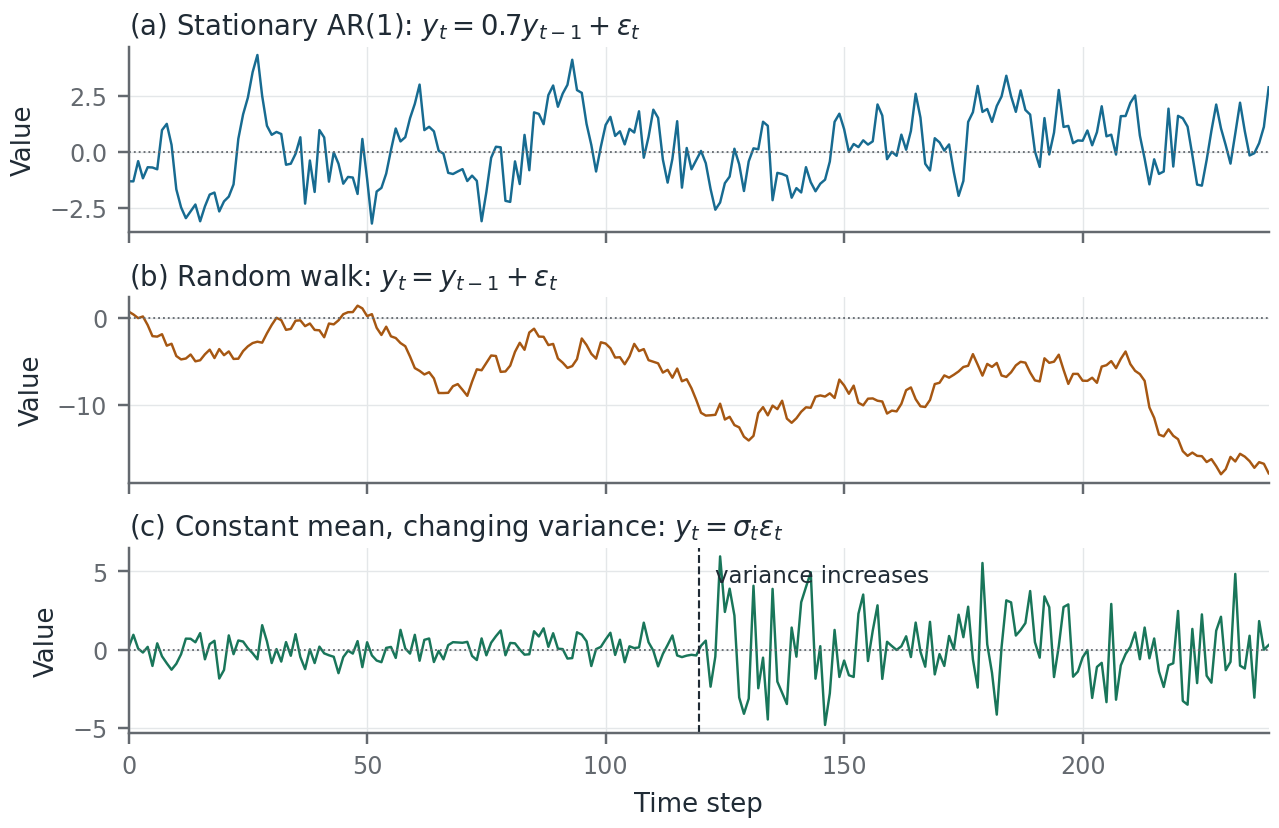

In [9]:
figure_manifest = json.loads((ROOT / "figures/manifest.json").read_text())
print("Teaching figures:", ", ".join(figure_manifest["figures"]))
print("Provenance:", figure_manifest["provenance"])
display(Image(filename=str(ROOT / "figures/stationarity.png")))


## 8. Optional: rerun the models

The inspection above has not rerun any model. To reproduce model fitting and inference, first create the full environment in [README.md](README.md). This downloads packages and the pinned original Chronos checkpoint; the ETTh1 file is already bundled and checksum-checked. The saved manifest records the original versions, seeds and measured model runtimes. Reruns can vary with hardware, package versions and numerical libraries.

The command below is disabled by default. Uncomment it only after installing the full model environment. It runs all three models with the fixed chapter protocol and writes a **new** timestamped experiment under `runs/`. The bundled `results/` and `figures/` remain unchanged. An explicit `--output-dir` must name a fresh directory.

Changing data, origins, model budgets or decoding settings creates a separate experiment and must be documented as such. This notebook continues to inspect the bundled reference experiment; inspect the new run's outputs separately.


In [10]:
# environment = {**os.environ, "HF_HUB_DISABLE_XET": "1", "OMP_NUM_THREADS": "2"}
# subprocess.run([sys.executable, str(ROOT / "scripts/run_zoo.py"), "--models", "all"],
#                cwd=ROOT, env=environment, check=True)
print("Optional model rerun is disabled; all inspection cells completed using saved outputs.")


Optional model rerun is disabled; all inspection cells completed using saved outputs.


## Extension: ETTh2

Before downloading or evaluating ETTh2, write down the target, its units, split endpoints, 96-hour horizon, three origins, information cutoffs, training budgets, sample count and scores. Reuse the scoring code and plotting structure. Verify ETTh2's timestamps, missingness, revision and checksum rather than assuming ETTh1's data identity transfers. Keep model selection away from the new test outcomes, and record pretraining overlap as unknown unless checkpoint-specific evidence resolves it.
